# Phase 6 — Matplotlib & Seaborn Exploratory Data Analysis

## Objective

In this notebook, we will perform Exploratory Data Analysis (EDA) on the cleaned airline flight dataset.

The main goals are:

- Understand airline operational performance
- Analyze departure and arrival delays
- Identify delay patterns
- Analyze cancellations and diversions
- Study monthly and weekly trends
- Analyze major delay causes
- Compare airports and routes
- Visualize relationships between operational variables
- Generate business-oriented insights

This notebook focuses on data visualization and exploratory analysis using:

- Matplotlib
- Seaborn
- Pandas

The cleaned dataset created in Notebook 1 will be used as the source for analysis.

## 1. Import Required Libraries

We will use:

- Pandas for working with the cleaned dataset
- NumPy for numerical operations where required
- Matplotlib for creating charts
- Seaborn for statistical and analytical visualizations

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

## 2. Load the Cleaned Dataset

The raw dataset was cleaned and validated in Notebook 1.

Therefore, we will not repeat the cleaning process here.

We will directly load the cleaned dataset for visualization and EDA.

In [53]:
cleaned_df = pd.read_csv(
    r"F:\Data science\intern all file\project\Airlines project final intern\data\cleaned_data\cleaned_flight_delay.csv"
)
cleaned_df.shape

(3000000, 39)

In [54]:
cleaned_df.head()

,FL_DATE,AIRLINE,AIRLINE_DOT,AIRLINE_CODE,DOT_CODE,FL_NUMBER,ORIGIN,ORIGIN_CITY,DEST,DEST_CITY,...,DELAY_DUE_NAS,DELAY_DUE_SECURITY,DELAY_DUE_LATE_AIRCRAFT,TOTAL_DELAY_CAUSE_MINUTES,DELAY_SEVERITY,YEAR,MONTH,DAY,DAY_OF_WEEK,ROUTE
0,2019-01-09,United Air Lines Inc.,United Air Lines Inc.: UA,UA,19977,1562,FLL,"Fort Lauderdale, FL",EWR,"Newark, NJ",...,NaN,NaN,NaN,0.0,ON_TIME,2019,1,9,Wednesday,FLL → EWR
1,2022-11-19,Delta Air Lines Inc.,Delta Air Lines Inc.: DL,DL,19790,1149,MSP,"Minneapolis, MN",SEA,"Seattle, WA",...,NaN,NaN,NaN,0.0,ON_TIME,2022,11,19,Saturday,MSP → SEA
2,2022-07-22,United Air Lines Inc.,United Air Lines Inc.: UA,UA,19977,459,DEN,"Denver, CO",MSP,"Minneapolis, MN",...,NaN,NaN,NaN,0.0,ON_TIME,2022,7,22,Friday,DEN → MSP
3,2023-03-06,Delta Air Lines Inc.,Delta Air Lines Inc.: DL,DL,19790,2295,MSP,"Minneapolis, MN",SFO,"San Francisco, CA",...,24.0,0.0,0.0,24.0,MODERATE_DELAY,2023,3,6,Monday,MSP → SFO
4,2020-02-23,Spirit Air Lines,Spirit Air Lines: NK,NK,20416,407,MCO,"Orlando, FL",DFW,"Dallas/Fort Worth, TX",...,NaN,NaN,NaN,0.0,ON_TIME,2020,2,23,Sunday,MCO → DFW


## 3. Verify the Dataset Before EDA

Before creating visualizations, we will quickly verify:

- Dataset dimensions
- Column names
- Data types
- Missing values in important analytical columns

This is a validation step rather than a new cleaning process.

In [55]:
cleaned_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000000 entries, 0 to 2999999
Data columns (total 39 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   FL_DATE                    str    
 1   AIRLINE                    str    
 2   AIRLINE_DOT                str    
 3   AIRLINE_CODE               str    
 4   DOT_CODE                   int64  
 5   FL_NUMBER                  int64  
 6   ORIGIN                     str    
 7   ORIGIN_CITY                str    
 8   DEST                       str    
 9   DEST_CITY                  str    
 10  CRS_DEP_TIME               int64  
 11  DEP_TIME                   float64
 12  DEP_DELAY                  float64
 13  TAXI_OUT                   float64
 14  WHEELS_OFF                 float64
 15  WHEELS_ON                  float64
 16  TAXI_IN                    float64
 17  CRS_ARR_TIME               int64  
 18  ARR_TIME                   float64
 19  ARR_DELAY                  float64
 20  CANCELLED    

In [56]:
cleaned_df[
    ["AIRLINE", "DEP_DELAY", "ARR_DELAY", "CANCELLED", "DIVERTED"]
].isna().sum()

AIRLINE          0
DEP_DELAY    77644
ARR_DELAY    86198
CANCELLED        0
DIVERTED         0
dtype: int64

## 4. EDA Questions

Instead of creating charts randomly, we will answer business questions through visualization.

### Business Questions

1. Which airlines operate the most flights?
2. Which airlines have higher average arrival delays?
3. How are arrival delays distributed?
4. How common are severe delays?
5. How do cancellations and diversions vary?
6. Are delays changing across months?
7. Which days of the week have higher delays?
8. What are the major reported causes of delays?
9. Which airports show higher delay risk?
10. Which routes experience higher delays?
11. Which operational variables are related to delays?

Each visualization will be connected to one or more of these questions.## 4. EDA Questions

Instead of creating charts randomly, we will answer business questions through visualization.

### Business Questions

1. Which airlines operate the most flights?
2. Which airlines have higher average arrival delays?
3. How are arrival delays distributed?
4. How common are severe delays?
5. How do cancellations and diversions vary?
6. Are delays changing across months?
7. Which days of the week have higher delays?
8. What are the major reported causes of delays?
9. Which airports show higher delay risk?
10. Which routes experience higher delays?
11. Which operational variables are related to delays?

Each visualization will be connected to one or more of these questions.

## 5. Airline Flight Volume

### Business Question

Which airlines operate the highest number of flights in the dataset?

Flight volume is important because an airline with a large number of flights has a different operational scale from an airline with a smaller network.

We will aggregate the number of flights by airline and visualize the result using a bar chart.

In [57]:
airline_volume = (
    cleaned_df
    .groupby("AIRLINE")
    .size()
    .sort_values(ascending=False)
)

airline_volume

AIRLINE
Southwest Airlines Co.                576470
Delta Air Lines Inc.                  395239
American Airlines Inc.                383106
SkyWest Airlines Inc.                 343737
United Air Lines Inc.                 254504
Republic Airline                      143107
Envoy Air                             121256
JetBlue Airways                       112844
Endeavor Air Inc.                     112463
PSA Airlines Inc.                     107050
Alaska Airlines Inc.                  100467
Spirit Air Lines                       95711
Mesa Airlines Inc.                     65012
Frontier Airlines Inc.                 64466
Allegiant Air                          52738
Hawaiian Airlines Inc.                 32114
Horizon Air                            20634
ExpressJet Airlines LLC d/b/a aha!     19082
dtype: int64

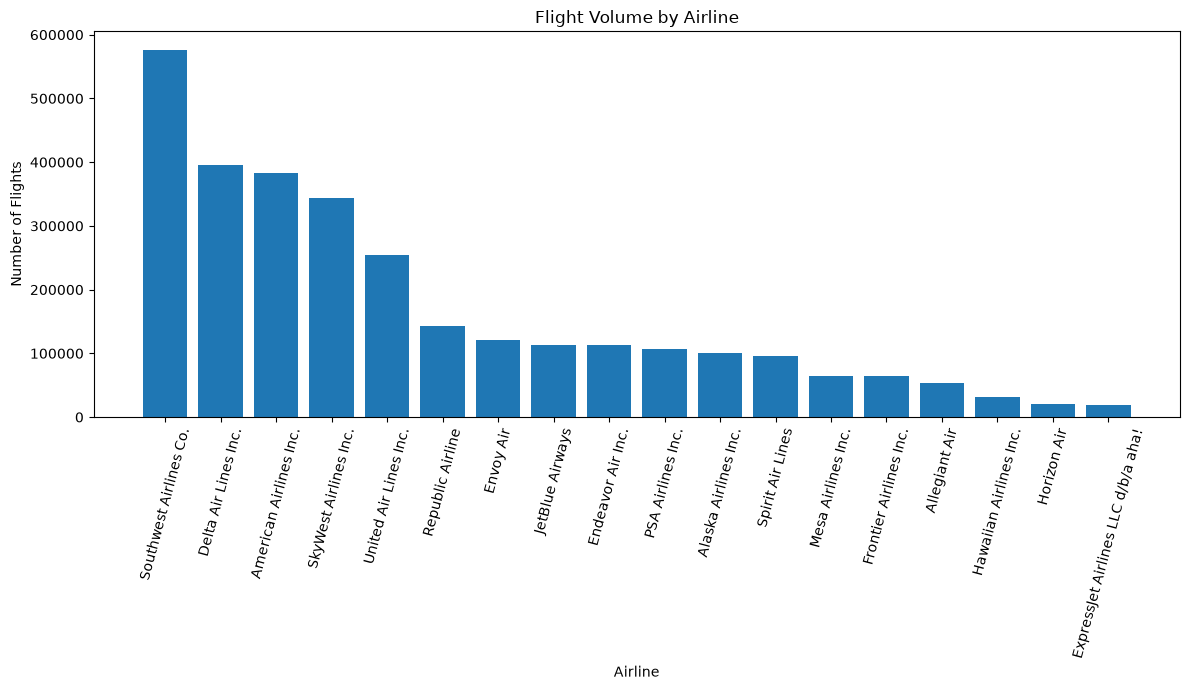

In [58]:
plt.figure(figsize=(12, 7))

plt.bar(
    airline_volume.index,
    airline_volume.values
)

plt.title("Flight Volume by Airline")
plt.xlabel("Airline")
plt.ylabel("Number of Flights")
plt.xticks(rotation=75)

plt.tight_layout()
plt.show()

### Interpretation

This chart shows the operational scale of each airline based on the number of flights in the dataset.

Airlines with higher flight volume contribute more observations to the dataset, while airlines with lower volume operate at a smaller scale within this dataset.

Flight volume should be considered when comparing airline performance because a small airline and a large airline should not be interpreted solely from raw flight counts.

## 6. Airline Average Arrival Delay

### Business Question

Which airlines have higher average arrival delays?

Average arrival delay provides a direct measure of the typical delay experienced at arrival.

We will calculate the average `ARR_DELAY` for each airline and visualize the result.

In [59]:
airline_arr_delay = (
    cleaned_df
    .groupby("AIRLINE")["ARR_DELAY"]
    .mean()
    .sort_values(ascending=False)
)

airline_arr_delay

AIRLINE
Allegiant Air                         13.284601
JetBlue Airways                       12.276125
Frontier Airlines Inc.                11.100429
ExpressJet Airlines LLC d/b/a aha!    10.031976
Spirit Air Lines                       8.029485
Mesa Airlines Inc.                     7.309810
American Airlines Inc.                 6.661229
United Air Lines Inc.                  5.035985
SkyWest Airlines Inc.                  4.023311
PSA Airlines Inc.                      3.928655
Hawaiian Airlines Inc.                 3.894757
Envoy Air                              3.278914
Southwest Airlines Co.                 3.269796
Horizon Air                            2.376242
Alaska Airlines Inc.                   1.097900
Delta Air Lines Inc.                   1.085079
Republic Airline                       0.590176
Endeavor Air Inc.                     -1.258539
Name: ARR_DELAY, dtype: float64

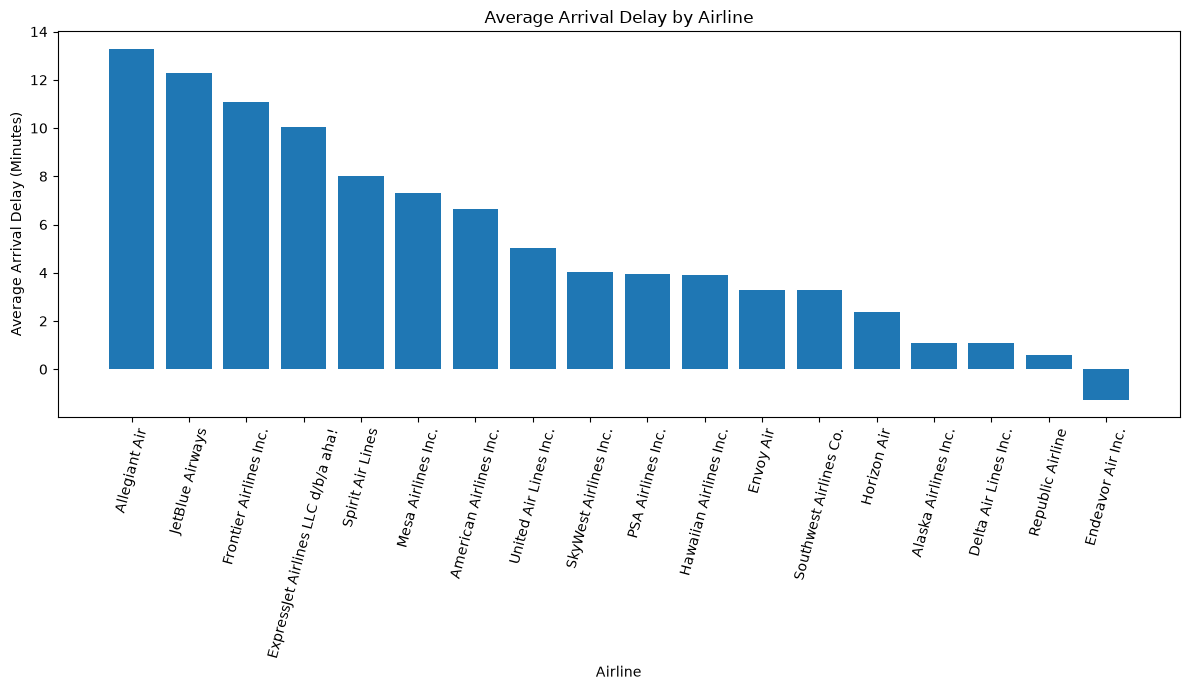

In [60]:
plt.figure(figsize=(12, 7))

plt.bar(
    airline_arr_delay.index,
    airline_arr_delay.values
)

plt.title("Average Arrival Delay by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.xticks(rotation=75)

plt.tight_layout()
plt.show()

### Business Interpretation

The chart allows us to compare airlines based on their average arrival delay.

A higher average arrival delay indicates that, on average, flights from that airline arrive later than their scheduled arrival time.

However, average delay alone does not fully describe airline performance. Later in the project, we will also consider:

- Flight volume
- Cancellation rate
- Diversion rate
- Delay frequency
- Delay severity
- Delay causes

This prevents us from judging an airline using only one metric.

## 7. Seaborn Bar Plot

The previous visualization used Matplotlib directly.

Now we will create a similar analytical chart using Seaborn.

Seaborn provides a higher-level interface for statistical visualization and works naturally with Pandas DataFrames.

In [61]:
airline_delay_df = (
    cleaned_df
    .groupby("AIRLINE", as_index=False)["ARR_DELAY"]
    .mean()
    .sort_values("ARR_DELAY", ascending=False)
)

airline_delay_df

,AIRLINE,ARR_DELAY
1,Allegiant Air,13.284601
10,JetBlue Airways,12.276125
7,Frontier Airlines Inc.,11.100429
6,ExpressJet Airlines LLC d/b/a aha!,10.031976
16,Spirit Air Lines,8.029485
11,Mesa Airlines Inc.,7.309810
2,American Airlines Inc.,6.661229
17,United Air Lines Inc.,5.035985
14,SkyWest Airlines Inc.,4.023311
12,PSA Airlines Inc.,3.928655


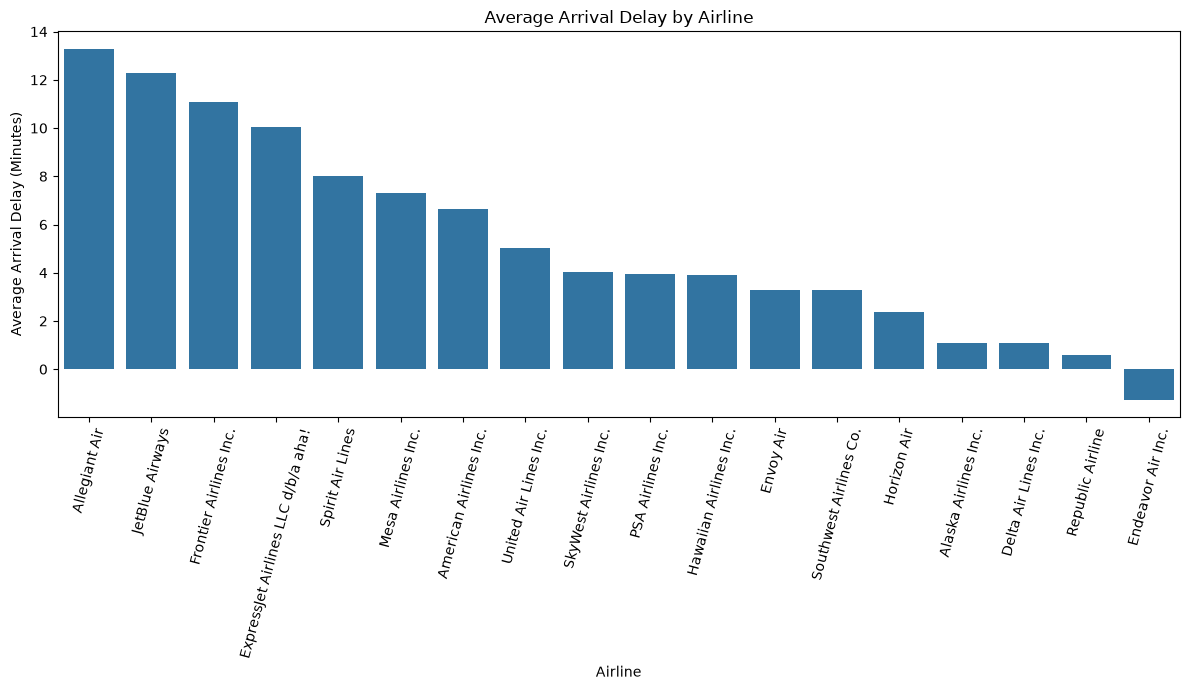

In [62]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=airline_delay_df,
    x="AIRLINE",
    y="ARR_DELAY"
)

plt.title("Average Arrival Delay by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.xticks(rotation=75)

plt.tight_layout()
plt.show()

### Matplotlib vs Seaborn

In this analysis:

- Matplotlib was used to build a chart directly from aggregated arrays.
- Seaborn was used with a Pandas DataFrame.
- Both approaches visualize the same business metric.
- Seaborn becomes especially useful for statistical plots and grouped comparisons.

We will use both libraries throughout this notebook according to the type of analysis.

## 8. Arrival Delay Distribution

### Business Question

How are arrival delays distributed across all flights?

Before comparing airlines, airports, or routes, we need to understand the overall distribution of arrival delays.

A histogram helps us identify:

- How many flights arrive early
- How many flights arrive close to schedule
- How frequently delays occur
- Whether extreme delays exist
- Whether the distribution is symmetric or skewed

Because the dataset contains 3 million flights, we will use a reproducible sample of the actual cleaned data for visualization performance.

This is not synthetic data. The observations come directly from the cleaned dataset.

In [63]:
arrival_delay_plot = (
    cleaned_df["ARR_DELAY"]
    .dropna()
    .sample(
        n=min(100000, cleaned_df["ARR_DELAY"].notna().sum()),
        random_state=42
    )
)

arrival_delay_plot.shape

(100000,)

### Histogram

A histogram divides arrival delays into intervals called bins and shows how many flights fall within each interval.

This helps us understand the frequency and spread of arrival delays.

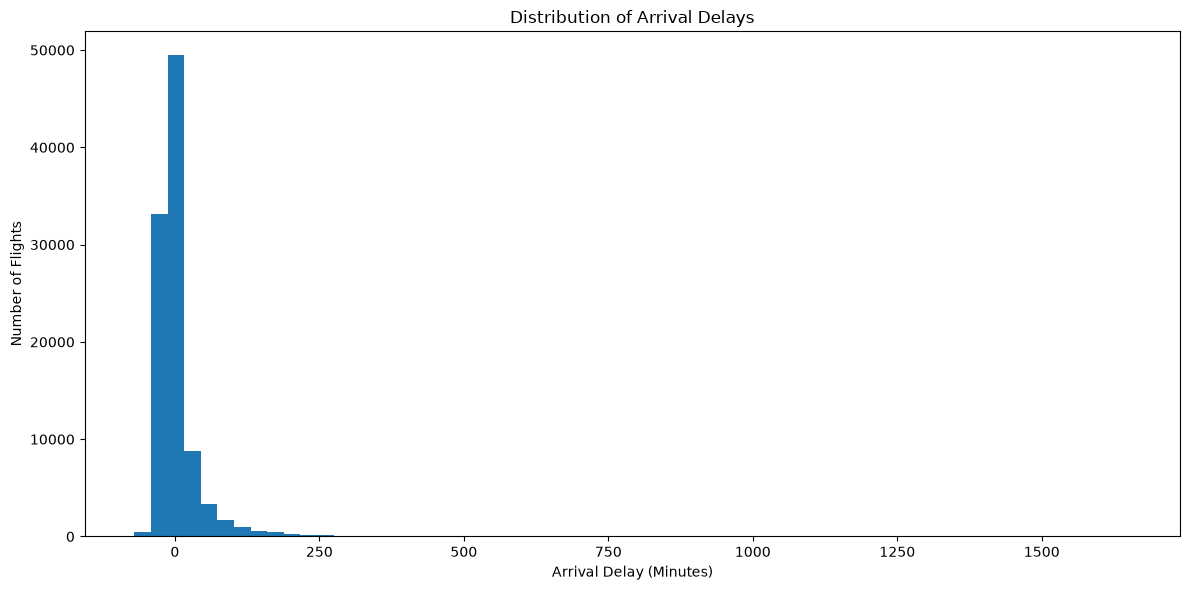

In [64]:
plt.figure(figsize=(12, 6))

plt.hist(
    arrival_delay_plot,
    bins=60
)

plt.title("Distribution of Arrival Delays")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Flights")

plt.tight_layout()
plt.show()

### Interpretation

The histogram shows the overall distribution of arrival delays.

The distribution is expected to contain both negative and positive values:

- Negative values represent flights that arrived earlier than scheduled.
- Values near zero represent flights arriving close to their scheduled time.
- Positive values represent late arrivals.
- Very large positive values represent extreme delays.

The presence of extreme positive values can make the distribution right-skewed.

## 9. Arrival Delay Distribution Using Seaborn

Seaborn provides statistical visualization functions that can make distribution patterns easier to explore.

We will use a histogram with a KDE curve.

The KDE (Kernel Density Estimate) provides a smooth estimate of the distribution shape.

### Algorithm idea — KDE

KDE estimates the probability density by placing a smooth curve around observed data points.

Conceptually:

1. Take each observed value.
2. Place a small smooth kernel around that value.
3. Combine the kernels.
4. The resulting curve represents the estimated distribution.

We use KDE here only for exploratory visualization, not for prediction or machine learning.

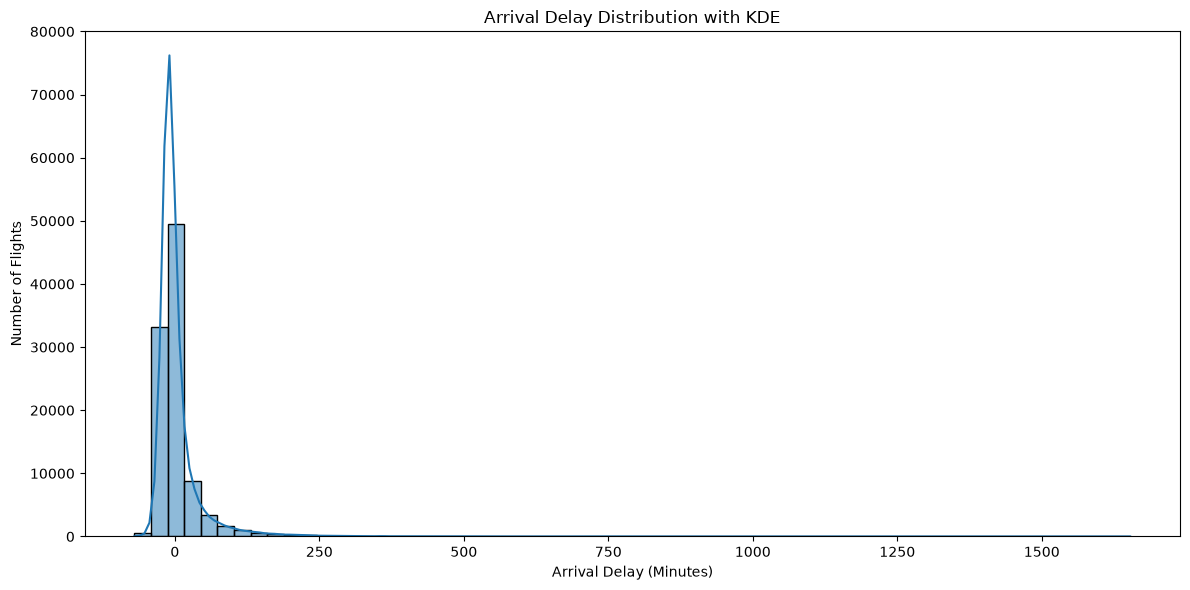

In [65]:
plt.figure(figsize=(12, 6))

sns.histplot(
    arrival_delay_plot,
    bins=60,
    kde=True
)

plt.title("Arrival Delay Distribution with KDE")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Flights")

plt.tight_layout()
plt.show()

### Business Interpretation

The distribution provides a high-level view of flight punctuality.

A concentration around zero indicates that many flights operate close to their scheduled arrival time, while the extended positive tail represents flights experiencing larger delays.

Extreme delays should be investigated separately because they can have a disproportionate operational impact.

## 10. Arrival Delay Boxplot

A boxplot provides a compact summary of the distribution.

It shows:

- Median
- Lower and upper quartiles
- Overall spread
- Potential outliers

This is particularly useful for identifying extreme arrival delays.

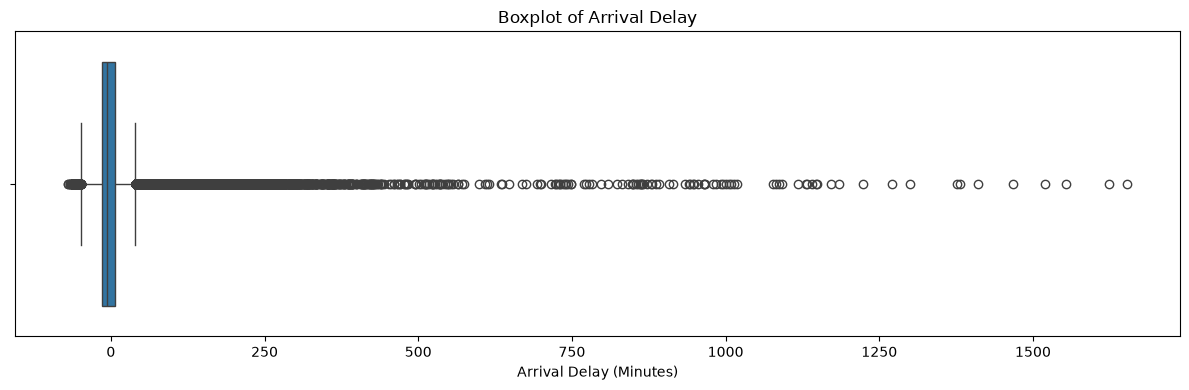

In [66]:
plt.figure(figsize=(12, 4))

sns.boxplot(
    x=arrival_delay_plot
)

plt.title("Boxplot of Arrival Delay")
plt.xlabel("Arrival Delay (Minutes)")

plt.tight_layout()
plt.show()

### Interpretation

The boxplot helps identify the central tendency and variability of arrival delays.

The points beyond the main distribution represent potential extreme observations.

These extreme values should not automatically be removed because very large flight delays can be genuine operational events.

Therefore, outliers will be analyzed rather than blindly deleted.

## 11. Arrival Delay Distribution by Airline

### Business Question

Do airlines differ only in their average delay, or also in the spread and extreme values of their delays?

A boxplot allows us to compare the median, variation, and potential outliers across airlines.

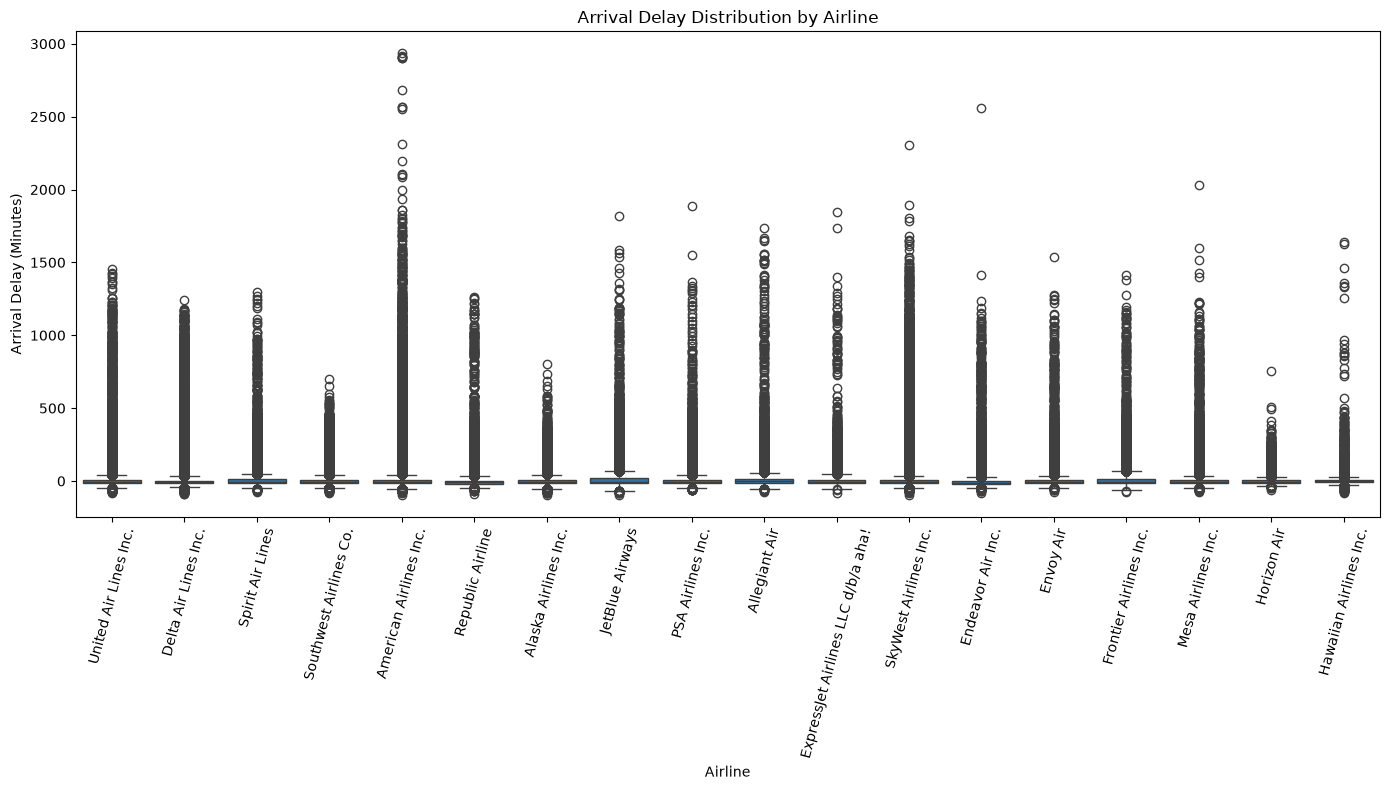

In [67]:
plt.figure(figsize=(14, 8))

sns.boxplot(
    data=cleaned_df,
    x="AIRLINE",
    y="ARR_DELAY"
)

plt.title("Arrival Delay Distribution by Airline")
plt.xlabel("Airline")
plt.ylabel("Arrival Delay (Minutes)")
plt.xticks(rotation=75)

plt.tight_layout()
plt.show()

### Interpretation

The boxplot shows that airlines can differ in:

- Typical arrival delay
- Variation in delay
- Presence of extreme delays

Therefore, average delay should not be used as the only airline-performance metric.

## 12. Departure Delay vs Arrival Delay

### Business Question

How strongly is departure delay reflected in arrival delay?

If a flight leaves late, we want to know whether that delay generally carries through to arrival.

In [68]:
delay_comparison = (
    cleaned_df[["DEP_DELAY", "ARR_DELAY"]]
    .dropna()
)

delay_comparison.shape

(2913802, 2)

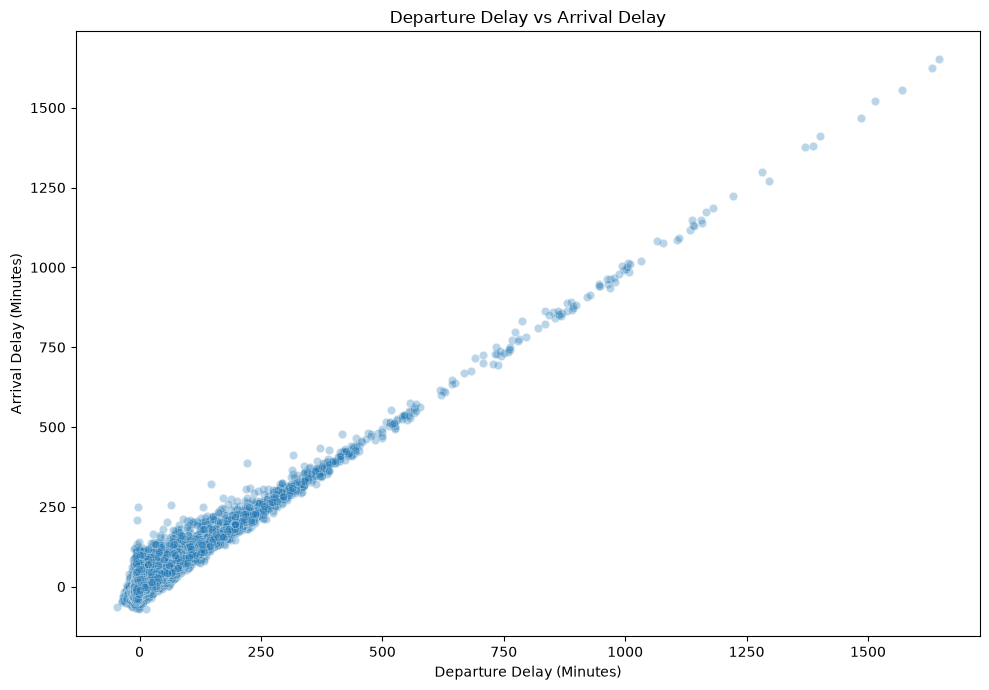

In [69]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=delay_comparison.sample(
        n=min(100000, len(delay_comparison)),
        random_state=42
    ),
    x="DEP_DELAY",
    y="ARR_DELAY",
    alpha=0.3
)

plt.title("Departure Delay vs Arrival Delay")
plt.xlabel("Departure Delay (Minutes)")
plt.ylabel("Arrival Delay (Minutes)")

plt.tight_layout()
plt.show()

### Interpretation

The scatter plot helps identify the relationship between departure and arrival delays.

A positive relationship indicates that flights departing late tend to also arrive late.

The spread of points shows that the relationship is not necessarily identical for every flight because factors such as taxi time, airborne time, and operational conditions can affect the final arrival delay.

## 13. Delay Severity Analysis

We created the `DELAY_SEVERITY` feature during the data-preparation phase.

Now we will visualize how flights are distributed across delay-severity categories.

### Business Question

What proportion of flights experience different levels of delay?

In [70]:
severity_counts = (
    cleaned_df["DELAY_SEVERITY"]
    .value_counts()
)

severity_counts

DELAY_SEVERITY
ON_TIME              2398513
MODERATE_DELAY        184218
SEVERE_DELAY          175135
SIGNIFICANT_DELAY     155936
UNKNOWN                86198
Name: count, dtype: int64

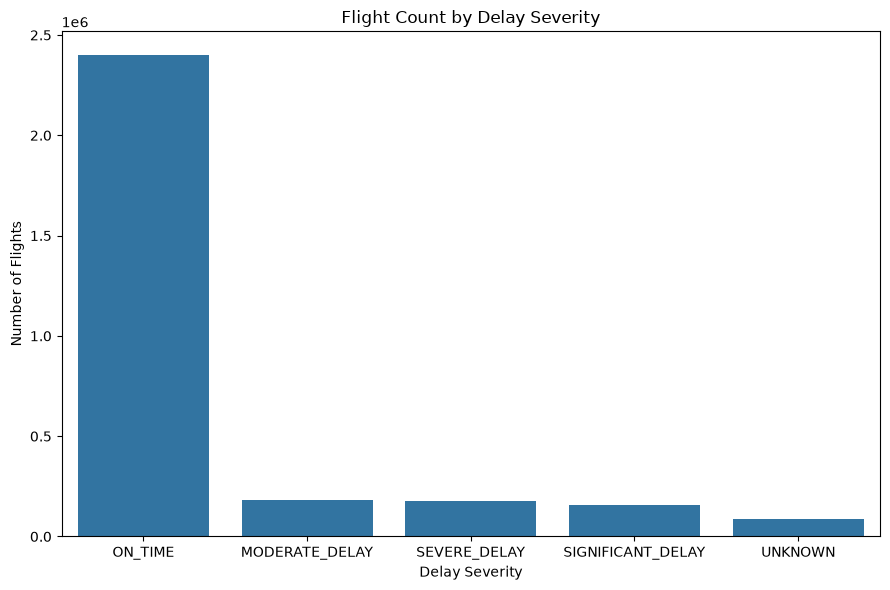

In [71]:
plt.figure(figsize=(9, 6))

sns.barplot(
    x=severity_counts.index,
    y=severity_counts.values
)

plt.title("Flight Count by Delay Severity")
plt.xlabel("Delay Severity")
plt.ylabel("Number of Flights")

plt.tight_layout()
plt.show()

### Interpretation

This visualization shows how frequently flights fall into each delay-severity category.

The result helps distinguish normal operations from moderate and severe operational disruptions.

Severe delays are particularly important from a business perspective because they can create larger passenger-service, aircraft-utilization, and scheduling impacts.

## 14. Cancellation Analysis

### Business Question

How many flights were cancelled, and what is the overall cancellation rate?

Cancellation is different from delay because the scheduled flight does not complete its planned operation.

In [72]:
cancellation_summary = (
    cleaned_df["CANCELLED"]
    .value_counts()
    .sort_index()
)

cancellation_summary

CANCELLED
0.0    2920860
1.0      79140
Name: count, dtype: int64

In [73]:
cancellation_rate = (
    cleaned_df["CANCELLED"].mean() * 100
)

cancellation_rate

np.float64(2.638)

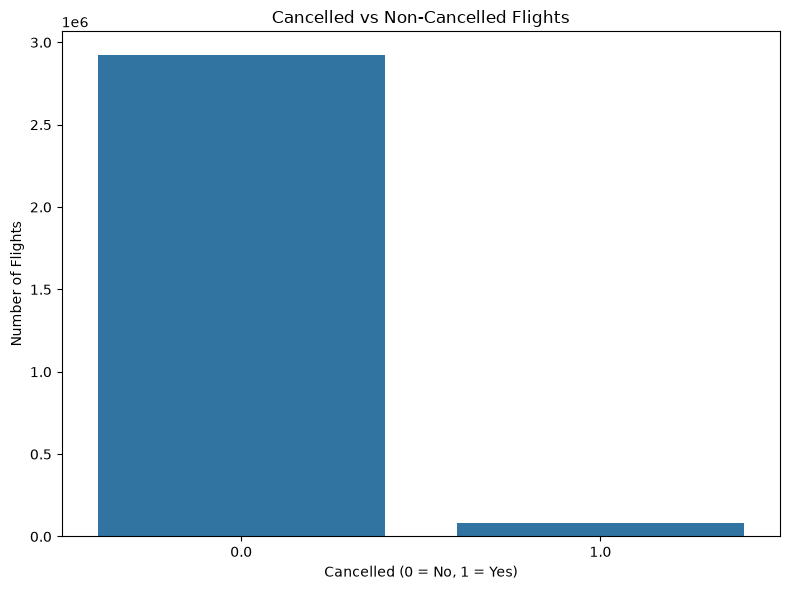

In [74]:
plt.figure(figsize=(8, 6))

sns.barplot(
    x=cancellation_summary.index.astype(str),
    y=cancellation_summary.values
)

plt.title("Cancelled vs Non-Cancelled Flights")
plt.xlabel("Cancelled (0 = No, 1 = Yes)")
plt.ylabel("Number of Flights")

plt.tight_layout()
plt.show()

### Interpretation

The cancellation analysis separates completed flights from cancelled operations.

The cancellation rate provides a more meaningful measure than the raw cancellation count because it accounts for the total number of flights.

## 15. Diversion Analysis

### Business Question

How common are flight diversions?

A diverted flight does not complete its planned arrival at the scheduled destination.

In [75]:
diversion_summary = (
    cleaned_df["DIVERTED"]
    .value_counts()
    .sort_index()
)

diversion_summary

DIVERTED
0.0    2992944
1.0       7056
Name: count, dtype: int64

In [76]:
diversion_rate = (
    cleaned_df["DIVERTED"].mean() * 100
)

diversion_rate

np.float64(0.2352)

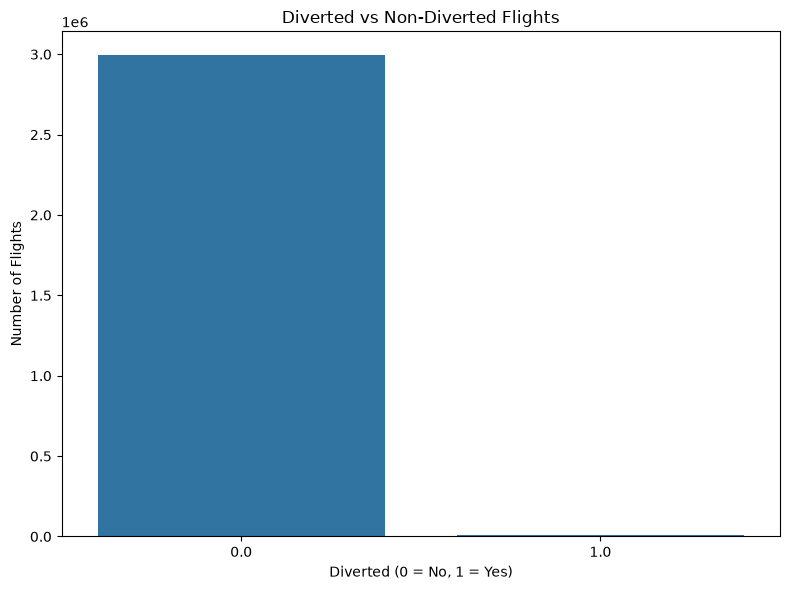

In [77]:
plt.figure(figsize=(8, 6))

sns.barplot(
    x=diversion_summary.index.astype(str),
    y=diversion_summary.values
)

plt.title("Diverted vs Non-Diverted Flights")
plt.xlabel("Diverted (0 = No, 1 = Yes)")
plt.ylabel("Number of Flights")

plt.tight_layout()
plt.show()

### Interpretation

Diversions are relatively uncommon compared with normal completed flights, but they represent important operational events.

The diversion rate should therefore be monitored alongside delays and cancellations when evaluating operational reliability.

## 16. Monthly Arrival Delay Trend

### Business Question

Does average arrival delay change across different months?

Monthly analysis can help identify seasonal patterns in flight operations.

In [78]:
monthly_delay = (
    cleaned_df
    .groupby("MONTH")["ARR_DELAY"]
    .mean()
)

monthly_delay

MONTH
1      2.190728
2      3.712646
3      2.255956
4      3.539976
5      3.359411
6     10.061753
7      9.491415
8      6.453106
9     -0.512181
10     1.424036
11     0.164154
12     6.672484
Name: ARR_DELAY, dtype: float64

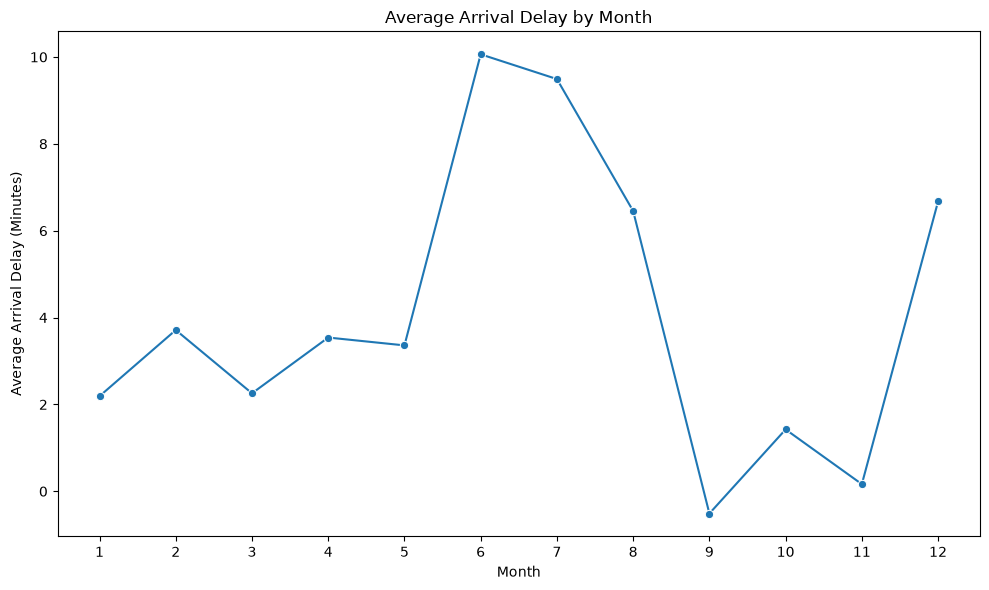

In [79]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    x=monthly_delay.index,
    y=monthly_delay.values,
    marker="o"
)

plt.title("Average Arrival Delay by Month")
plt.xlabel("Month")
plt.ylabel("Average Arrival Delay (Minutes)")

plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()

### Interpretation

The monthly trend shows how average arrival delay changes throughout the year.

Months with higher average delays may require additional operational attention.

Seasonality should be considered when evaluating airline performance because comparing airlines without considering time-related patterns may produce incomplete conclusions.

## 17. Arrival Delay by Day of Week

### Business Question

Are some days of the week associated with higher average arrival delays?

This analysis can help identify weekly operational patterns.

In [80]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekly_delay = (
    cleaned_df
    .groupby("DAY_OF_WEEK")["ARR_DELAY"]
    .mean()
    .reindex(day_order)
)

weekly_delay

DAY_OF_WEEK
Monday       4.717601
Tuesday      1.693007
Wednesday    2.632201
Thursday     5.563596
Friday       5.947104
Saturday     3.669612
Sunday       5.291464
Name: ARR_DELAY, dtype: float64

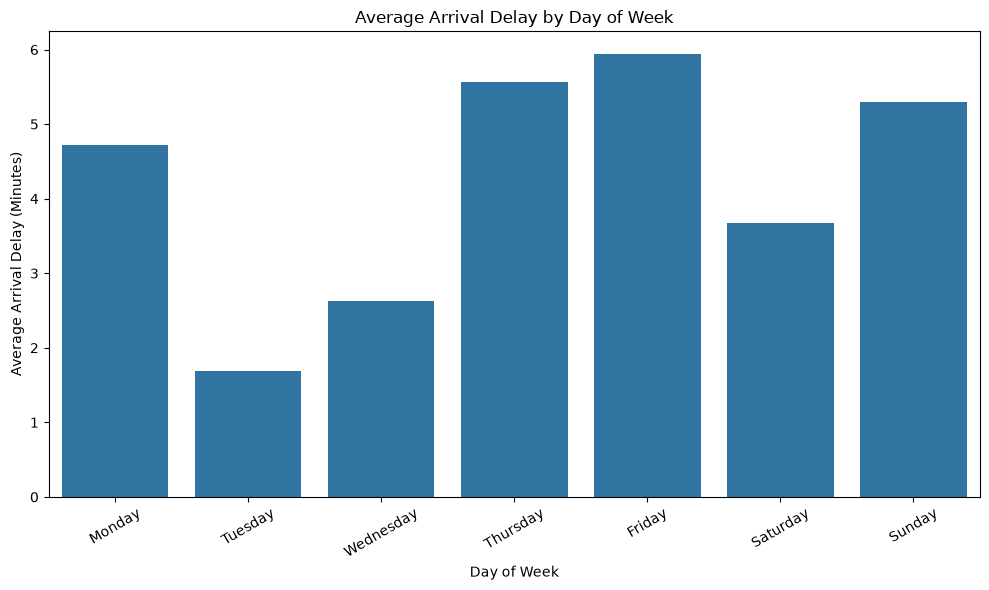

In [81]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=weekly_delay.index,
    y=weekly_delay.values
)

plt.title("Average Arrival Delay by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### Interpretation

The chart compares average arrival delays across the seven days of the week.

Differences between days may reflect variations in flight schedules, traffic levels, airport congestion, or operational conditions.

This analysis provides another dimension for understanding delay patterns.

## 18. Analysis of Reported Delay Causes

The dataset contains several reported delay-cause variables:

- Carrier delay
- Weather delay
- National Airspace System (NAS) delay
- Security delay
- Late aircraft delay

### Business Question

Which reported causes contribute the most delay minutes?

We will aggregate the reported delay minutes for each cause.

In [82]:
delay_causes = {
    "Carrier": "DELAY_DUE_CARRIER",
    "Weather": "DELAY_DUE_WEATHER",
    "NAS": "DELAY_DUE_NAS",
    "Security": "DELAY_DUE_SECURITY",
    "Late Aircraft": "DELAY_DUE_LATE_AIRCRAFT"
}

cause_totals = (
    cleaned_df[list(delay_causes.values())]
    .fillna(0)
    .sum()
    .rename(index={v: k for k, v in delay_causes.items()})
    .sort_values(ascending=False)
)

cause_totals

Late Aircraft    13598175.0
Carrier          13217960.0
NAS               7028161.0
Weather           2127583.0
Security            77907.0
dtype: float64

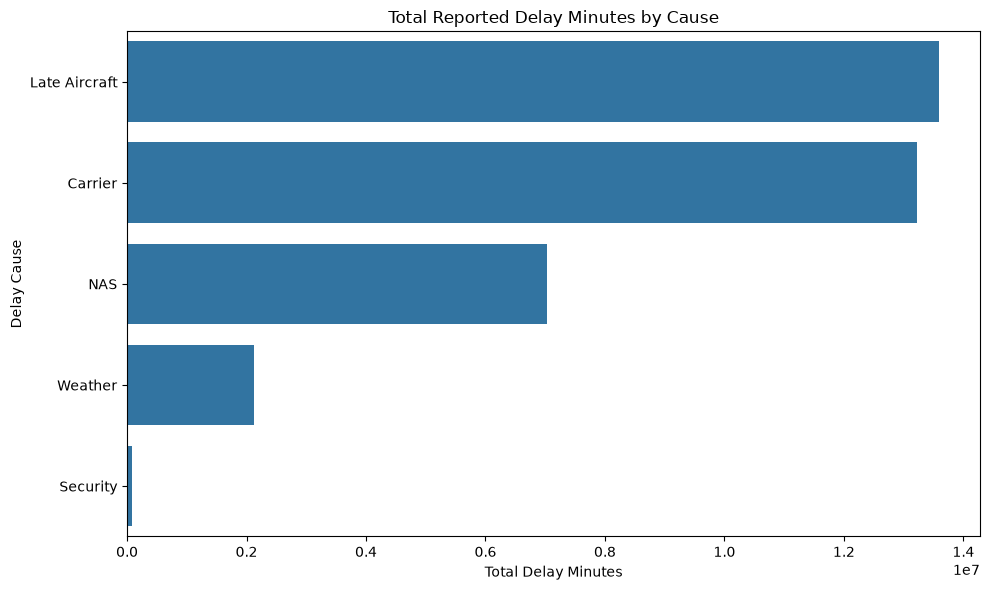

In [83]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=cause_totals.values,
    y=cause_totals.index
)

plt.title("Total Reported Delay Minutes by Cause")
plt.xlabel("Total Delay Minutes")
plt.ylabel("Delay Cause")

plt.tight_layout()
plt.show()

### Interpretation

This visualization identifies the major reported contributors to delay minutes.

The results can help management distinguish between causes that may be influenced internally and causes that are more dependent on external operating conditions.

For example, carrier and late-aircraft delays can provide insight into internal scheduling and operational processes, while weather-related delays are more externally driven.

## 19. Airport-Level Delay Analysis

### Business Question

Which origin airports have the highest average departure delays?

Airport-level analysis can reveal locations where operational congestion or scheduling conditions may contribute to delays.

To avoid conclusions based on airports with very few flights, we will first require a minimum flight volume.

In [84]:
airport_summary = (
    cleaned_df
    .groupby("ORIGIN")
    .agg(
        TOTAL_FLIGHTS=("ORIGIN", "size"),
        AVG_DEP_DELAY=("DEP_DELAY", "mean")
    )
)

airport_summary = airport_summary[
    airport_summary["TOTAL_FLIGHTS"] >= 1000
]

top_delay_airports = (
    airport_summary
    .sort_values("AVG_DEP_DELAY", ascending=False)
    .head(15)
)

top_delay_airports

,TOTAL_FLIGHTS,AVG_DEP_DELAY
ORIGIN,,
ASE,2859,25.889146
EGE,1325,17.754553
EWR,52989,16.063835
JAC,2432,14.732636
FLL,40276,14.673527
SJU,13009,14.636421
MCO,63883,14.567784
HPN,4433,14.473181
EYW,3493,14.102602


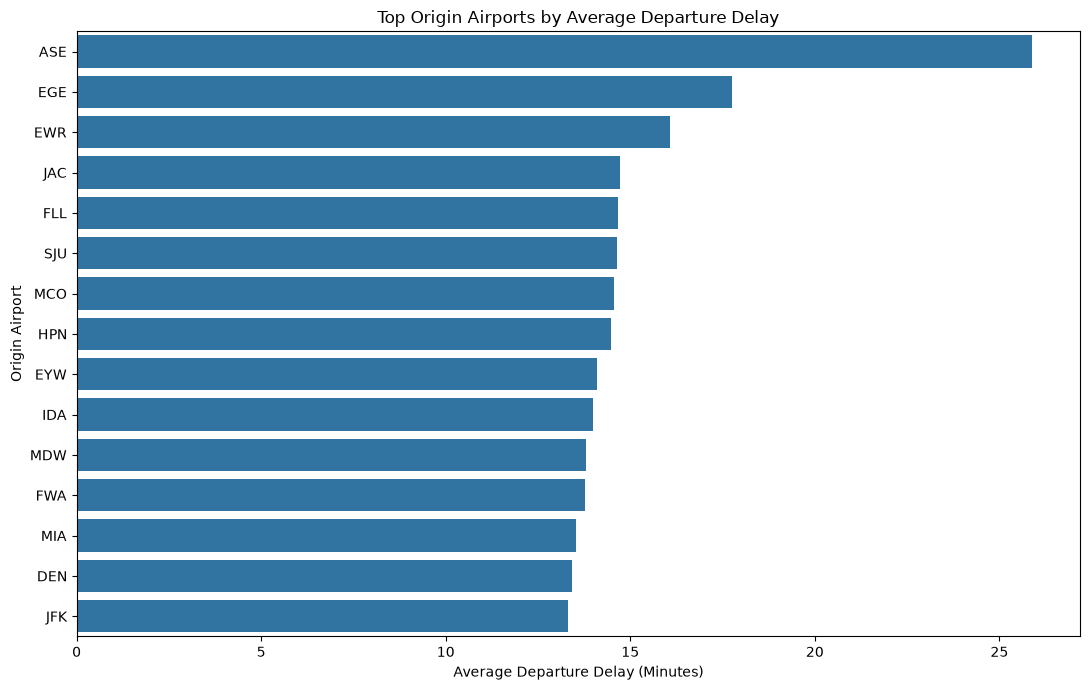

In [85]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_delay_airports.reset_index(),
    x="AVG_DEP_DELAY",
    y="ORIGIN"
)

plt.title("Top Origin Airports by Average Departure Delay")
plt.xlabel("Average Departure Delay (Minutes)")
plt.ylabel("Origin Airport")

plt.tight_layout()
plt.show()

## 20. Route-Level Delay Analysis

### Business Question

Which flight routes have higher average arrival delays?

Route analysis can reveal recurring operational challenges between specific origin-destination pairs.

A minimum flight-volume threshold is used to avoid ranking routes based on very small numbers of observations.

In [86]:
route_summary = (
    cleaned_df
    .groupby("ROUTE")
    .agg(
        TOTAL_FLIGHTS=("ROUTE", "size"),
        AVG_ARR_DELAY=("ARR_DELAY", "mean")
    )
)

route_summary = route_summary[
    route_summary["TOTAL_FLIGHTS"] >= 500
]

top_routes = (
    route_summary
    .sort_values("AVG_ARR_DELAY", ascending=False)
    .head(15)
)

top_routes

,TOTAL_FLIGHTS,AVG_ARR_DELAY
ROUTE,,
DEN → ASE,1002,21.248352
PNS → DFW,763,19.355062
MCO → JFK,1970,18.566492
FLL → JFK,1755,18.298246
DFW → HOU,1011,18.277719
SJU → EWR,949,18.207343
MCO → EWR,2853,18.151416
BHM → DFW,918,17.173563
MIA → JFK,2223,16.878184


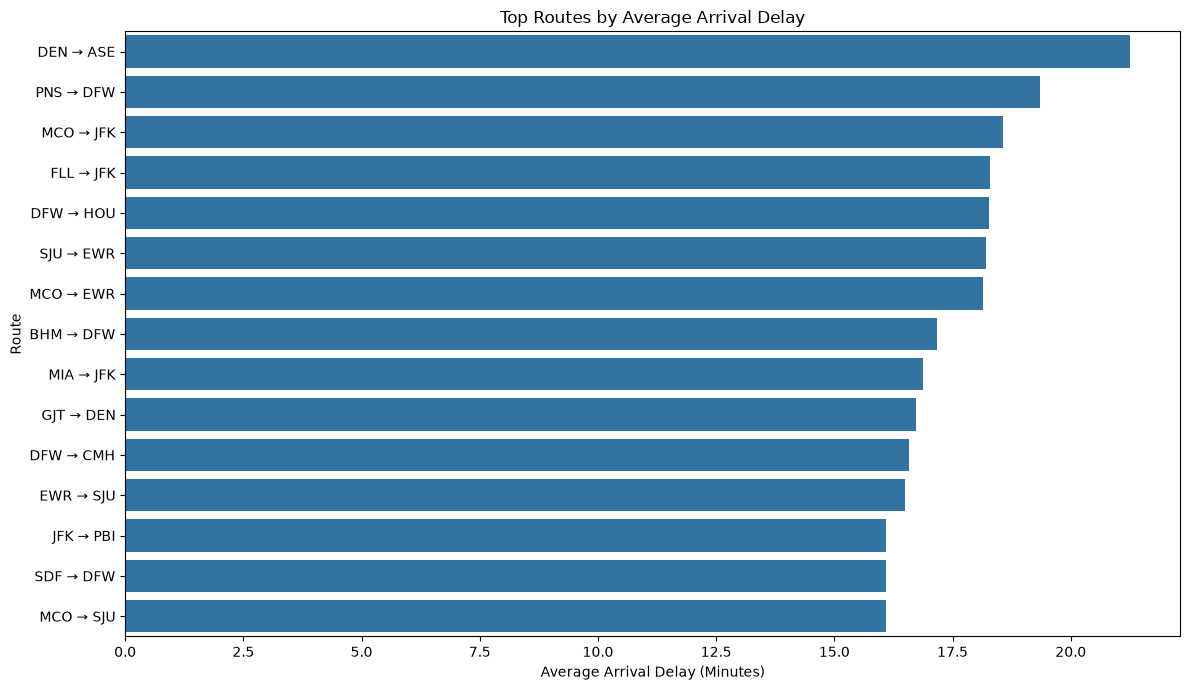

In [87]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_routes.reset_index(),
    x="AVG_ARR_DELAY",
    y="ROUTE"
)

plt.title("Top Routes by Average Arrival Delay")
plt.xlabel("Average Arrival Delay (Minutes)")
plt.ylabel("Route")

plt.tight_layout()
plt.show()

## 21. Airline × Month Delay Heatmap

### Business Question

Does an airline's average delay change significantly across different months?

A heatmap allows us to compare two dimensions simultaneously:

- Airline
- Month

The color intensity represents average arrival delay.

In [88]:
airline_month_delay = (
    cleaned_df
    .pivot_table(
        index="AIRLINE",
        columns="MONTH",
        values="ARR_DELAY",
        aggfunc="mean"
    )
)

airline_month_delay

MONTH,1,2,3,4,5,6,7,8,9,10,11,12
AIRLINE,,,,,,,,,,,,
Alaska Airlines Inc.,1.499943,3.082346,-0.587647,0.123157,-1.180531,2.466704,1.375362,2.372907,-1.567297,-2.547411,-0.235635,8.230962
Allegiant Air,9.611672,10.355121,11.335202,14.350942,9.051544,17.743800,21.291947,13.870666,6.712201,10.982164,9.764048,15.561110
American Airlines Inc.,2.165527,5.574381,4.296357,5.312337,6.912361,15.344644,13.880675,9.988562,1.116763,4.224578,1.577043,5.973017
Delta Air Lines Inc.,-0.988837,0.462834,-0.057361,1.073820,-0.291619,5.576998,6.071615,2.903539,-3.149870,-1.929366,-1.761670,3.169496
Endeavor Air Inc.,-0.471555,-0.472713,-3.001876,-1.906257,-3.243735,4.088166,1.805569,0.668742,-5.233710,-2.971782,-4.310499,-1.582469
Envoy Air,3.592616,5.392232,0.707142,1.030616,3.434450,7.050249,5.739682,3.994348,0.571766,1.938266,0.392133,4.401901
ExpressJet Airlines LLC d/b/a aha!,6.993609,8.873185,1.428319,8.198987,10.354724,24.052491,15.850689,21.168666,7.823351,10.812903,1.086564,13.817223
Frontier Airlines Inc.,5.421808,7.455273,9.691390,12.549727,12.869247,17.631607,19.056003,15.779871,3.323339,7.770327,6.082064,11.353055
Hawaiian Airlines Inc.,2.342327,2.979267,4.964858,4.681021,5.043223,3.052299,4.156716,1.492725,-0.595735,5.892760,3.625337,9.751620


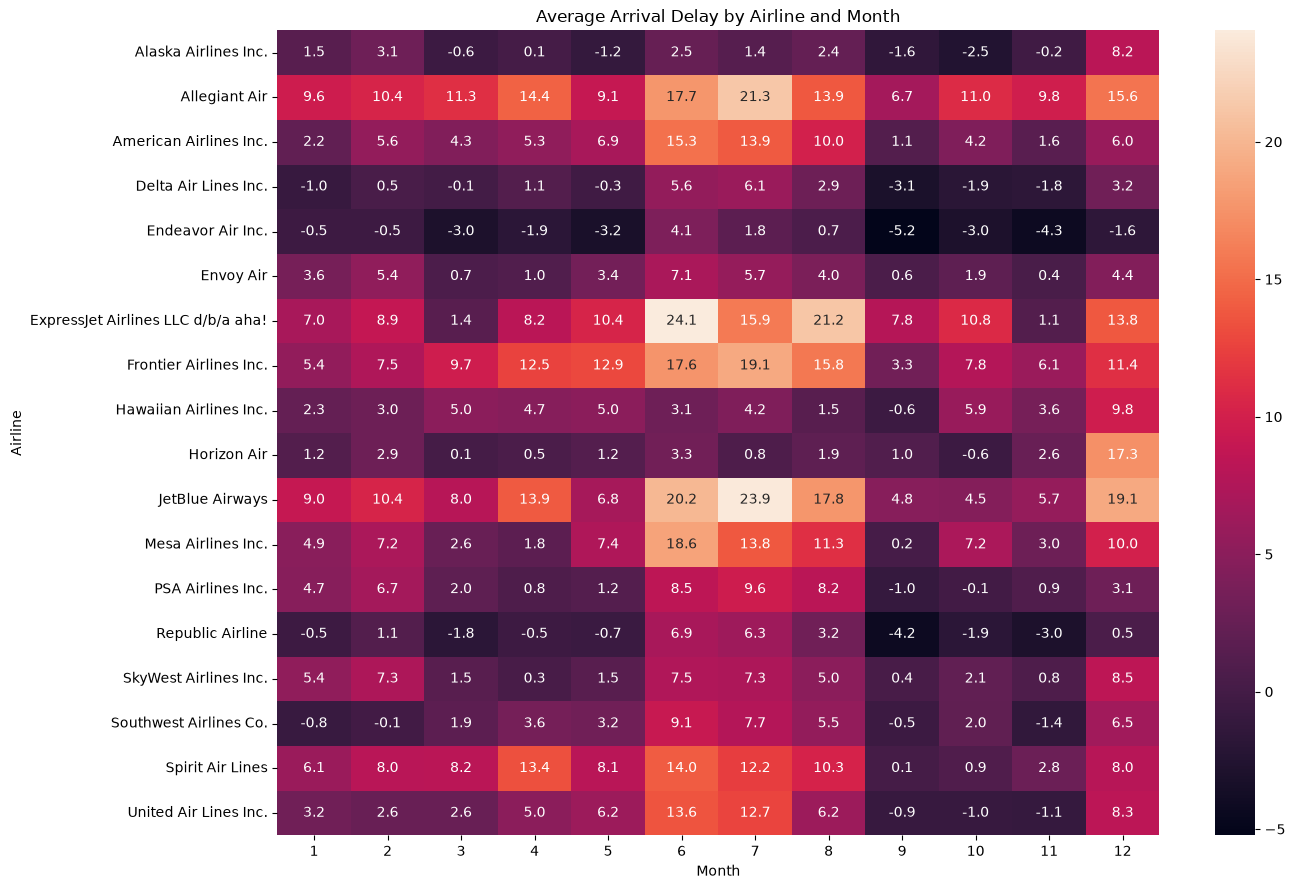

In [89]:
plt.figure(figsize=(14, 9))

sns.heatmap(
    airline_month_delay,
    annot=True,
    fmt=".1f"
)

plt.title("Average Arrival Delay by Airline and Month")
plt.xlabel("Month")
plt.ylabel("Airline")

plt.tight_layout()
plt.show()

### Interpretation

The heatmap provides a combined view of airline and seasonal delay patterns.

It helps identify:

- Airlines with consistently higher delays
- Months with elevated delays
- Airlines whose performance changes substantially across months

This is more informative than analyzing airline and month independently.

## 22. Correlation Analysis

### Business Question

Which numerical operational variables have relationships with arrival delay?

Correlation measures the strength and direction of a linear relationship between numerical variables.

The correlation coefficient ranges from -1 to +1:

- +1 → strong positive relationship
- 0 → little or no linear relationship
- -1 → strong negative relationship

Correlation does not prove causation.

In [90]:
correlation_columns = [
    "DEP_DELAY",
    "TAXI_OUT",
    "TAXI_IN",
    "AIR_TIME",
    "DISTANCE",
    "ARR_DELAY"
]

correlation_matrix = (
    cleaned_df[correlation_columns]
    .corr()
)

correlation_matrix

,DEP_DELAY,TAXI_OUT,TAXI_IN,AIR_TIME,DISTANCE,ARR_DELAY
DEP_DELAY,1.000000,0.052870,0.018658,0.020928,0.022136,0.964805
TAXI_OUT,0.052870,1.000000,0.025477,0.057060,0.043013,0.194940
TAXI_IN,0.018658,0.025477,1.000000,0.082961,0.074733,0.110939
AIR_TIME,0.020928,0.057060,0.082961,1.000000,0.983873,0.017156
DISTANCE,0.022136,0.043013,0.074733,0.983873,1.000000,0.001884
ARR_DELAY,0.964805,0.194940,0.110939,0.017156,0.001884,1.000000


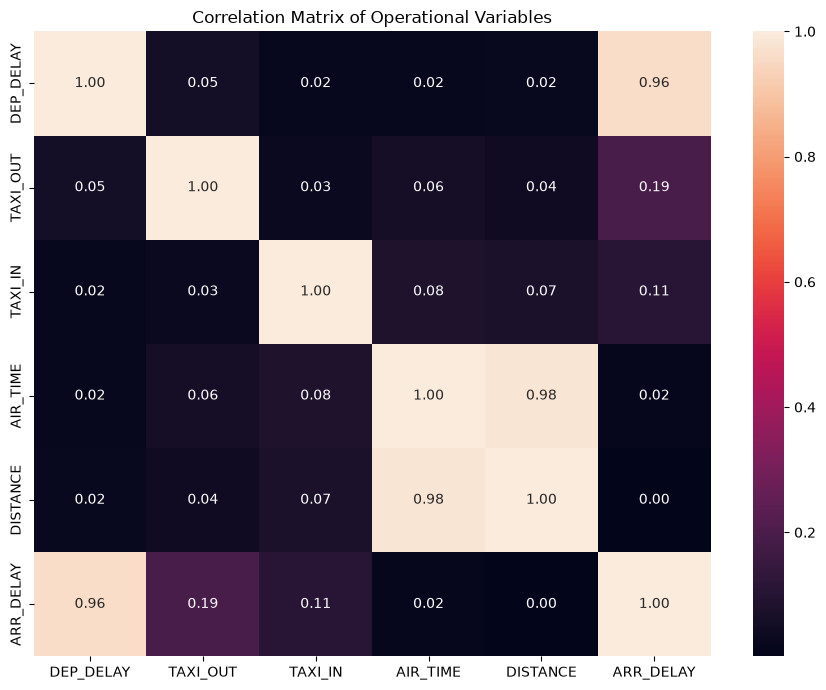

In [91]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix of Operational Variables")

plt.tight_layout()
plt.show()

### Interpretation

The correlation matrix helps identify numerical variables that move together.

In particular, the relationship between departure delay and arrival delay is important for understanding whether delays are carried forward during a flight's operation.

Correlation should be interpreted as an exploratory relationship rather than proof that one variable causes another.

## 23. Distance vs Arrival Delay

### Business Question

Is flight distance associated with arrival delay?

Because the dataset contains millions of observations, a reproducible sample of actual flights will be used for the scatter plot to keep the visualization readable and efficient.

In [92]:
distance_delay_sample = (
    cleaned_df[
        ["DISTANCE", "ARR_DELAY"]
    ]
    .dropna()
    .sample(
        n=min(100000, len(cleaned_df.dropna(subset=["DISTANCE", "ARR_DELAY"]))),
        random_state=42
    )
)

distance_delay_sample.shape

(100000, 2)

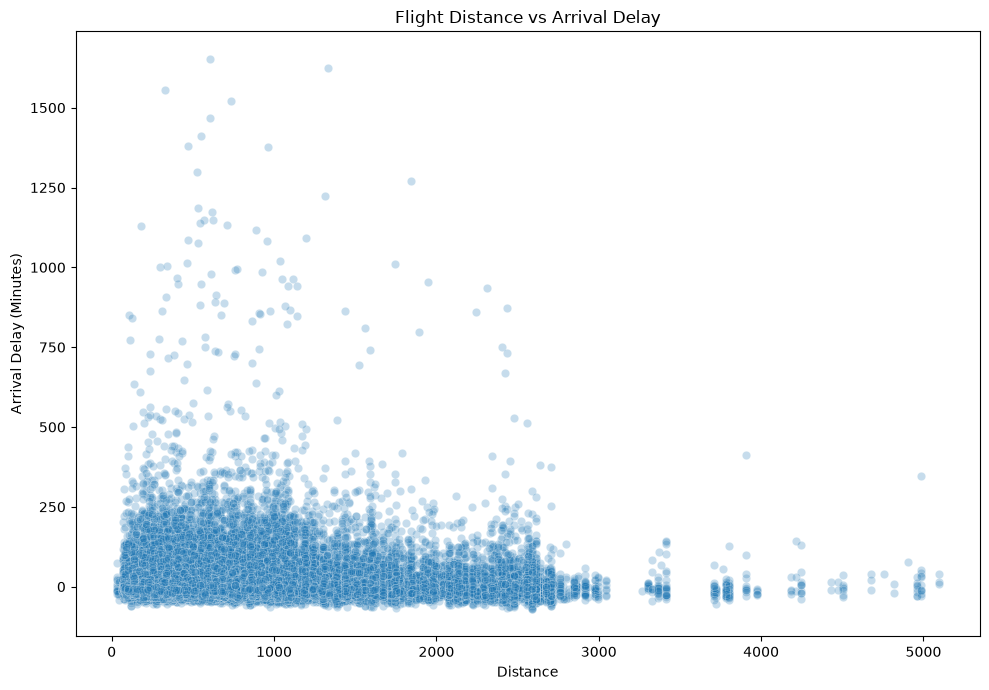

In [93]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=distance_delay_sample,
    x="DISTANCE",
    y="ARR_DELAY",
    alpha=0.25
)

plt.title("Flight Distance vs Arrival Delay")
plt.xlabel("Distance")
plt.ylabel("Arrival Delay (Minutes)")

plt.tight_layout()
plt.show()

## 24. Extreme Delay Analysis

### Business Question

How many flights experienced extremely large arrival delays?

Extreme delays are important because they may have a much greater operational and customer impact than ordinary delays.

We will define an extreme delay as an arrival delay greater than 180 minutes.

In [94]:
extreme_delay_flights = (
    cleaned_df["ARR_DELAY"] > 180
).sum()

extreme_delay_flights

np.int64(32263)

In [95]:
extreme_delay_rate = (
    extreme_delay_flights / cleaned_df["ARR_DELAY"].notna().sum()
) * 100

extreme_delay_rate

np.float64(1.1072475068656003)

In [96]:
extreme_by_airline = (
    cleaned_df[
        cleaned_df["ARR_DELAY"] > 180
    ]
    .groupby("AIRLINE")
    .size()
    .sort_values(ascending=False)
    .head(10)
)

extreme_by_airline

AIRLINE
American Airlines Inc.    5188
SkyWest Airlines Inc.     4585
Delta Air Lines Inc.      3700
United Air Lines Inc.     3246
Southwest Airlines Co.    2948
JetBlue Airways           2588
Spirit Air Lines          1355
Republic Airline          1310
PSA Airlines Inc.         1219
Frontier Airlines Inc.    1076
dtype: int64

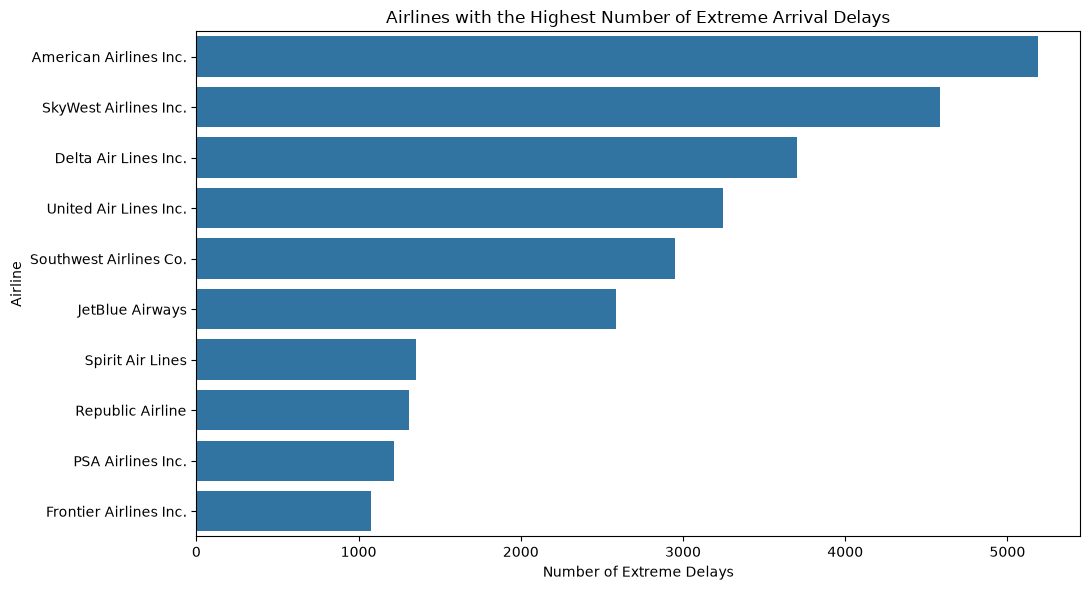

In [97]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=extreme_by_airline.values,
    y=extreme_by_airline.index
)

plt.title("Airlines with the Highest Number of Extreme Arrival Delays")
plt.xlabel("Number of Extreme Delays")
plt.ylabel("Airline")

plt.tight_layout()
plt.show()

## 25. Save Important Visualizations

Important charts should be saved separately so they can later be used in:

- Project documentation
- README
- Presentation
- Tableau preparation
- Portfolio demonstrations

In [98]:
import os

os.makedirs("visualizations", exist_ok=True)

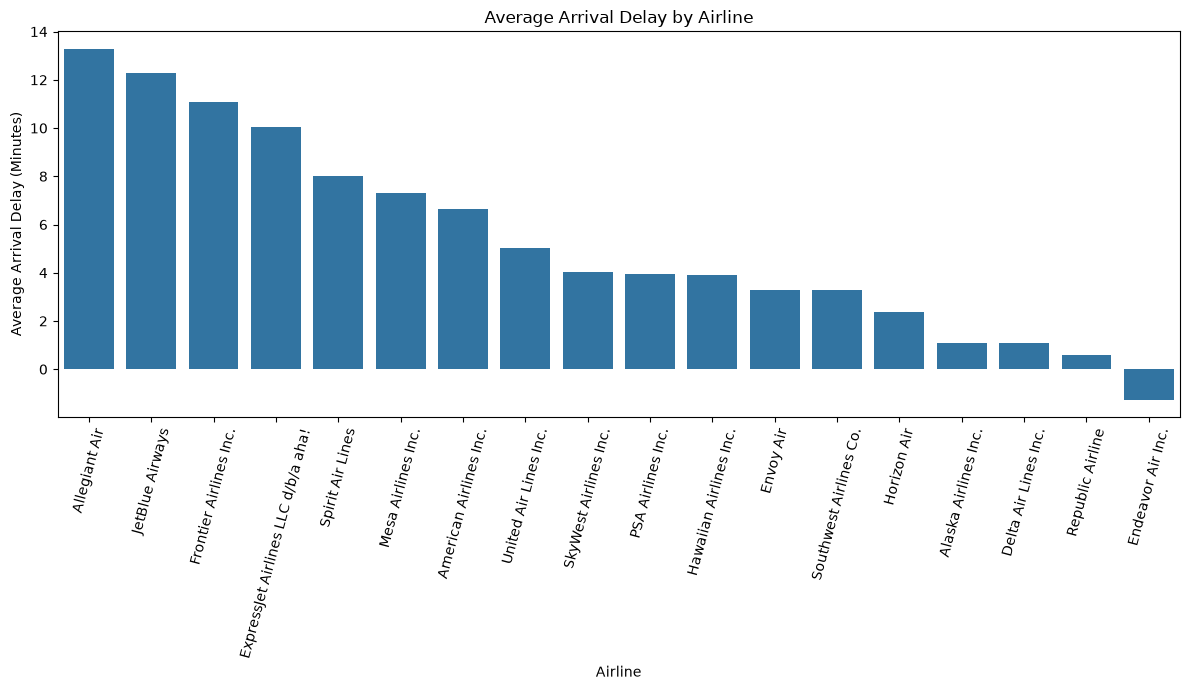

In [99]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=airline_delay_df,
    x="AIRLINE",
    y="ARR_DELAY"
)

plt.title("Average Arrival Delay by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.xticks(rotation=75)

plt.tight_layout()

plt.savefig(
    "visualizations/average_arrival_delay_by_airline.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 26. Final EDA Business Insights

The exploratory analysis examined airline performance, delay distributions, operational trends, delay causes, airports, routes, and relationships between numerical variables.

### Key Areas Investigated

1. Airline flight volume
2. Average arrival delay
3. Delay distribution
4. Delay severity
5. Cancellation rate
6. Diversion rate
7. Monthly delay patterns
8. Weekly delay patterns
9. Reported delay causes
10. Airport-level performance
11. Route-level performance
12. Airline-month performance
13. Correlation between operational variables
14. Distance and arrival delay
15. Extreme arrival delays

### Business Perspective

The analysis demonstrates that airline operational performance should not be evaluated using a single metric.

A stronger assessment combines:

- Flight volume
- Average delay
- Delay frequency
- Delay severity
- Cancellation rate
- Diversion rate
- Delay causes
- Airport performance
- Route performance
- Seasonal patterns

These findings can later be transformed into SQL analytical queries and Tableau dashboards.

## 27. Phase 6 Validation

Before moving to the SQL phase, verify that the major EDA requirements have been completed.

### Validation Checklist

- [x] Matplotlib used
- [x] Seaborn used
- [x] Airline comparison completed
- [x] Delay distribution analyzed
- [x] Boxplot analysis completed
- [x] Cancellation analysis completed
- [x] Diversion analysis completed
- [x] Monthly trend analyzed
- [x] Weekly trend analyzed
- [x] Delay causes analyzed
- [x] Airport analysis completed
- [x] Route analysis completed
- [x] Heatmap created
- [x] Correlation analysis completed
- [x] Scatter analysis completed
- [x] Extreme delay analysis completed
- [x] Important visualization saved
- [x] Business insights documented

## Phase 6 Status: COMPLETE

In [100]:
phase_6_status = {
    "Matplotlib": "Complete",
    "Seaborn": "Complete",
    "EDA": "Complete",
    "Business_Insights": "Complete",
    "Visualization_Saving": "Complete"
}

phase_6_status

{'Matplotlib': 'Complete',
 'Seaborn': 'Complete',
 'EDA': 'Complete',
 'Business_Insights': 'Complete',
 'Visualization_Saving': 'Complete'}